In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\shash\OneDrive\Desktop\Airbnb_Pricing_Analytics\data\processed\listings_clean.csv")
priced = df[df["is_priced"] == True]
print(len(priced))

6377


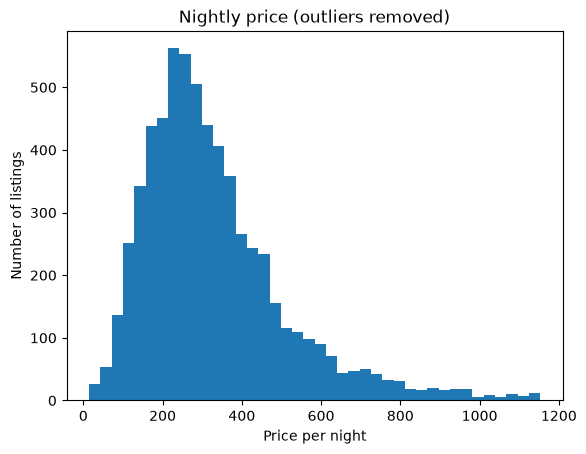

In [2]:
normal = priced[priced["price_outlier"] == False]

plt.hist(normal["price_num"], bins=40)
plt.title("Nightly price (outliers removed)")
plt.xlabel("Price per night")
plt.ylabel("Number of listings")
plt.show()

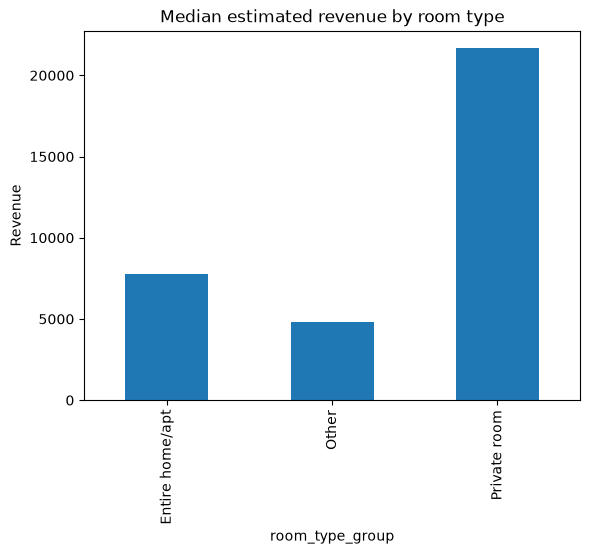

In [3]:
by_room = priced.groupby("room_type_group")["estimated_revenue_l365d"].median()

by_room.plot(kind="bar")
plt.title("Median estimated revenue by room type")
plt.ylabel("Revenue")
plt.show()

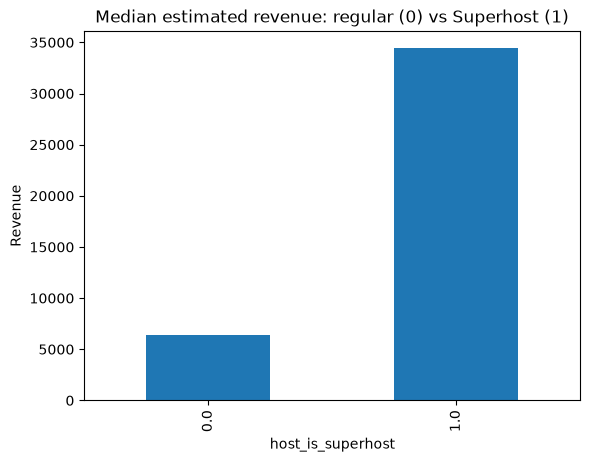

In [4]:
by_host = priced.groupby("host_is_superhost")["estimated_revenue_l365d"].median()

by_host.plot(kind="bar")
plt.title("Median estimated revenue: regular (0) vs Superhost (1)")
plt.ylabel("Revenue")
plt.show()

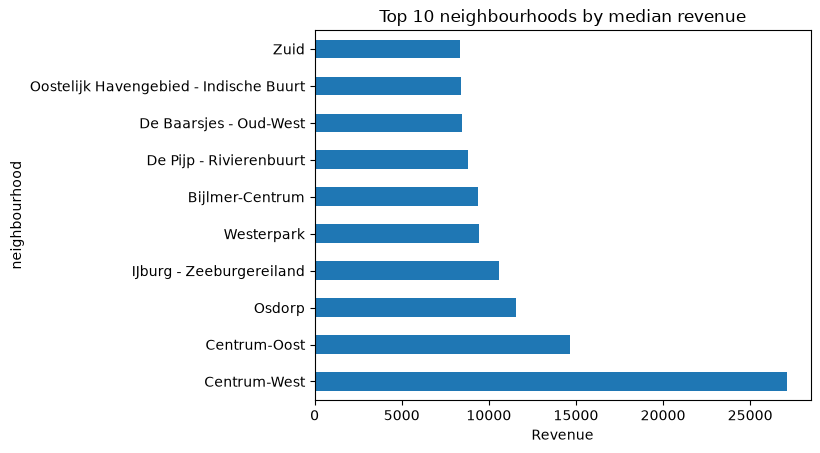

In [5]:
counts = priced.groupby("neighbourhood")["price_num"].count()
big_areas = counts[counts >= 30].index

big = priced[priced["neighbourhood"].isin(big_areas)]
top10 = big.groupby("neighbourhood")["estimated_revenue_l365d"].median().sort_values(ascending=False).head(10)

top10.plot(kind="barh")
plt.title("Top 10 neighbourhoods by median revenue")
plt.xlabel("Revenue")
plt.show()